# 01 · Data Collection — X and Reddit

**Project:** Mapping Polarization and Cross-Community Interaction in the Cockroach Janta Party (CJP)-led Jantar Mantar Protests (Group 9).
**Window:** 1 June – 31 July 2026 (UTC). **Primary platform:** X. **Secondary platform (comparison):** Reddit.

This notebook documents how both datasets were collected and, for Reddit, contains the collector itself.
Set `RUN_COLLECTION = True` to re-download (takes several hours because the public archives are rate-limited);
by default it summarises the raw files already on disk.

In [1]:
import sys, json, re, time, os, datetime
sys.path.insert(0, '.')
from csma_lib import *
setup_plots()
RUN_COLLECTION = False          # True = call the archive APIs again (hours); False = summarise cached raw files
print('project root:', ROOT)

project root: /Users/CSMA/Project


## 1. X (Twitter) — browser capture with Zeeschuimer + Schuifmaat

X has no free research API, so posts were captured from the logged-in web interface with two Firefox extensions:
**Zeeschuimer** (Digital Methods Initiative; captures the JSON that X sends to the browser while a search page is open and exports it as a 4CAT-style CSV) and **Schuifmaat** (auto-scrolls the result page so that the full timeline of a search loads).
Each search used X's advanced-search date filter for 1 June – 31 July 2026. Searches were organised in keyword groups that mirror the research design:

| Group | Focus | Example queries |
|---|---|---|
| A | Entity-specific: the organiser of the protest | `"Cockroach Janta Party" protest`, `CJP "Jantar Mantar"`, `Jantar Mantar Protestors`, `कॉकरोच जनता पार्टी` |
| B | Topic-specific: the exam issue | `CJP NEET-UG`, `"NEET aspirants" "Jantar Mantar"`, `"paper leak" "Jantar Mantar"` |
| C | Government / state response | `CJP government`, `"Jantar Mantar" government`, `"Jantar Mantar" "Delhi Police"`, `"Jantar Mantar" "Education Minister"` |
| D | Student unions (searched on X with several keyword sets; too few posts returned, covered on Reddit only) | `AISA "Jantar Mantar"`, `SFI CJP`, `NSUI NEET protest`, `ABVP CJP`, `"Cockroach Students"` |

Group D on X stays empty; the same queries did return material on Reddit (notebook 01, section 2). Any later X capture can be dropped into `data/x_raw/Group D/` and notebooks 02 onwards re-run.

In [2]:
rows = []
for gdir in sorted(X_RAW.iterdir()):
    if not gdir.is_dir(): continue
    for f in sorted(gdir.glob('*.csv')):
        with open(f, encoding='utf-8-sig', errors='replace') as fh:
            header = fh.readline()
        sep = ';' if header.count(';') > header.count(',') else ','
        df = pd.read_csv(f, sep=sep, engine='python', dtype=str, keep_default_na=False, encoding='utf-8-sig', encoding_errors='replace', on_bad_lines='skip')
        ts = pd.to_datetime(df.get('timestamp', pd.Series(dtype=str)), errors='coerce')
        rows.append({'group': gdir.name, 'file': f.name, 'rows': len(df), 'columns': df.shape[1],
                     'first_post': ts.min(), 'last_post': ts.max(), 'in_window': int(((ts >= WINDOW_START) & (ts <= WINDOW_END)).sum())})
x_inventory = pd.DataFrame(rows)
save_table(x_inventory, '01_x_raw_inventory')
x_inventory

table saved: outputs/tables/01_x_raw_inventory.csv  (12 rows)


,group,file,rows,columns,first_post,last_post,in_window
0,Group A,1_CJP_Protest_cleaned_filtered.csv,232,44,2026-06-01 07:37:39,2026-07-31 07:33:48,232
1,Group A,2_CJP_JantarMantar_cleaned_filtered.csv,338,44,2026-06-01 07:37:39,2026-07-31 18:12:52,338
2,Group A,3rd Jantar Mantar Protestors.csv,680,44,2026-06-04 02:29:05,2026-07-31 13:59:14,680
3,Group A,4th कॉकरोच जनता पार्टी.csv,220,44,2026-06-01 08:40:04,2026-07-31 08:35:31,220
4,Group B,4_CJP_NEET-UG_cleaned_filtered.csv,145,44,2026-06-01 12:37:43,2026-07-31 20:58:27,145
5,Group B,_NEET aspirants_ _Jantar Mantar_.csv,50,44,2023-02-07 02:40:42,2026-09-28 08:57:04,40
6,Group B,_paper leak_ _Jantar Mantar_.csv,292,44,2018-03-28 16:56:13,2026-09-30 15:05:47,133
7,Group C,3a_CJP_Government_Original_cleaned_filtered.csv,45,44,2026-06-06 03:43:33,2026-07-31 16:26:13,45
8,Group C,3b_CJP_Government_AdvSearch_cleaned_filtered.csv,42,44,2026-06-05 20:17:07,2026-07-30 04:15:00,42
9,Group C,Jantar Mantar_ _Delhi Police.csv,747,44,2026-06-01 09:37:18,2026-07-31 14:47:21,747


**What this shows:** 12 Zeeschuimer exports in three keyword groups (Group D is still empty). Several exports contain posts outside the study window; notebook 02 keeps only the window and removes duplicates across files.

## 2. Reddit — public archive APIs (PullPush + Arctic Shift)

Reddit's own API needs registered credentials and blocks anonymous JSON requests, so the collector uses two public archives of Reddit that are standard in research: **PullPush** (keyword search over submissions and comments, 100 items per page, ~15 requests per minute) and **Arctic Shift** (full comment threads by post id).
The same four keyword groups were used, plus the three CJP subreddits. Every submission is tagged with the queries that matched it, so a post can belong to several groups, exactly as on X.

Stages (all resumable): **1** keyword submissions → **2** full comment threads of every matched submission with comments → **1b** comments that mention core terms anywhere on Reddit.

In [3]:
QUERIES = {
  "A": ['"Cockroach Janta Party"', 'CJP', '"Abhijeet Dipke"', 'Dipke', '"cockroach party"', 'cockroachjantaparty',
        '"Saurav Das"', '"Ashutosh Ranka"', '"Vijeta Dahiya"', '"Cockroach is Back"', '"cockroach janta"'],
  "B": ['NEET protest', '"paper leak"', '"Dharmendra Pradhan"', '"Pradhan resign"', '"education minister"',
        '"NEET-UG"', 'NTA protest', 'NEET scam', '"exam manifesto"', 'NEET "Jantar Mantar"'],
  "C": ['"Jantar Mantar"', '"Delhi Police" protest', '"Sonam Wangchuk"', 'Wangchuk', '"lathi charge"', '"Chalo Sansad"',
        '"Parliament march"', '"tear gas" Delhi', '"B-team"', '"foreign funding"', 'Nadda CJP', '"hunger strike" Delhi',
        '"Pradhan Go Back"', '"Delhi Metro" protest', 'Kejriwal "Jantar Mantar"'],
  "D": ['AISA protest', 'SFI protest', 'NSUI protest', 'ABVP protest', 'AISF', '"Cockroach Students"', '"student union" protest',
        '"JNU students"', '"Neha Bora"', '"Aishe Ghosh"', '"students protest" Delhi', '"Gen Z" protest India', 'KYS protest'],
}
SUBREDDITS = ["cockroachjantaparty", "CockroachJantaParty09", "CJP_Protest_"]
COMMENT_TERMS = ['"Cockroach Janta"', 'CJP', 'Dipke', '"Jantar Mantar"', '"Dharmendra Pradhan"', 'Wangchuk', '"paper leak"', '"cockroach party"', 'Pradhan resign']
AFTER, BEFORE = 1780272000, 1785542399    # 2026-06-01 00:00:00 .. 2026-07-31 23:59:59 UTC
print(sum(len(v) for v in QUERIES.values()), 'keyword queries +', len(SUBREDDITS), 'subreddits;', len(COMMENT_TERMS), 'comment terms')

49 keyword queries + 3 subreddits; 9 comment terms


In [4]:
# The collector (identical to _build/collect_reddit.py and _build/collect_reddit_threads_as.py, which were run as
# background jobs so the notebook does not have to stay open for hours).
import urllib.request, urllib.parse, shutil
UA = "csma-research-bmu/0.1 (academic project)"
PP = "https://api.pullpush.io/reddit/search"
AS = "https://arctic-shift.photon-reddit.com/api/comments/search"

def api_get(url, pace=4.0, tries=6):
    for t in range(tries):
        try:
            with urllib.request.urlopen(urllib.request.Request(url, headers={"User-Agent": UA}), timeout=90) as r:
                time.sleep(pace); return json.loads(r.read().decode("utf8"))
        except urllib.error.HTTPError as e:
            time.sleep(30 * (2 ** t) if e.code in (429, 422) else 8 * (t + 1))
        except Exception:
            time.sleep(10 * (t + 1))
    return None

def pullpush_pages(kind, params, max_pages=400):
    '''Newest-first pagination inside the window with a moving `before` cursor.'''
    before, pages, seen = BEFORE, 0, set()
    while pages < max_pages:
        q = dict(params, after=AFTER, before=before, size=100, sort="desc", sort_type="created_utc")
        js = api_get(f"{PP}/{kind}/?" + urllib.parse.urlencode(q, quote_via=urllib.parse.quote))
        data = [d for d in (js or {}).get("data", []) if d["id"] not in seen]
        if not data: break
        seen.update(d["id"] for d in data); pages += 1
        yield data
        before = min(d["created_utc"] for d in data) - 1
        if len(js["data"]) < 100: break

def arctic_thread(post_id, pace=2.5):
    '''All comments of one submission, oldest first, via Arctic Shift.'''
    got, after, pages = {}, AFTER - 1, 0
    while pages < 150:
        js = api_get(f"{AS}?" + urllib.parse.urlencode({"link_id": f"t3_{post_id}", "limit": 100, "sort": "asc", "after": after}), pace=pace)
        data = (js or {}).get("data") or []
        new = [c for c in data if c["id"] not in got]
        for c in new: got[c["id"]] = c
        pages += 1
        if len(data) < 100 or not new: break
        after = max(c["created_utc"] for c in data)
    return list(got.values())

def append_jsonl(path, rows):
    with open(path, "a") as fh:
        for r in rows: fh.write(json.dumps(r, ensure_ascii=False) + "\n")

if RUN_COLLECTION:
    R_RAW.mkdir(exist_ok=True); index = {}
    for g, qs in QUERIES.items():                                   # stage 1: submissions
        for q in qs:
            for page in pullpush_pages("submission", {"q": q}):
                fresh = [d for d in page if d["id"] not in index]
                for d in page: index.setdefault(d["id"], set()).add(f"{g}|{q}")
                append_jsonl(R_RAW / "submissions.jsonl", fresh)
    for s in SUBREDDITS:
        for page in pullpush_pages("submission", {"subreddit": s}):
            fresh = [d for d in page if d["id"] not in index]
            for d in page: index.setdefault(d["id"], set()).add(f"A|subreddit:{s}")
            append_jsonl(R_RAW / "submissions.jsonl", fresh)
    json.dump({k: sorted(v) for k, v in index.items()}, open(R_RAW / "submission_queries.json", "w"))
    subs = list(jsonl_iter(R_RAW / "submissions.jsonl"))
    for d in sorted(subs, key=lambda d: -(d.get("num_comments") or 0)):   # stage 2: threads
        if (d.get("num_comments") or 0) > 0:
            append_jsonl(R_RAW / "comments_threads_as.jsonl", arctic_thread(d["id"]))
    for term in COMMENT_TERMS:                                      # stage 1b: keyword comments
        for page in pullpush_pages("comment", {"q": term}, max_pages=120):
            for c in page: c["_matched_term"] = term
            append_jsonl(R_RAW / "comments_keyword.jsonl", page)
else:
    print('Using cached raw files in', R_RAW.relative_to(ROOT))

Using cached raw files in data/reddit_raw


In [5]:
# Inventory of the raw Reddit files
def count_jsonl(p):
    return sum(1 for _ in open(p)) if p.exists() else 0
subs = list(jsonl_iter(R_RAW / 'submissions.jsonl')) if (R_RAW / 'submissions.jsonl').exists() else []
index = json.load(open(R_RAW / 'submission_queries.json')) if (R_RAW / 'submission_queries.json').exists() else {}
state = json.load(open(R_RAW / 'state.json')) if (R_RAW / 'state.json').exists() else {}
state_as = json.load(open(R_RAW / 'state_as.json')) if (R_RAW / 'state_as.json').exists() else {}
n_threads = len(state.get('threads_done', {})) + len(state_as.get('threads_done', {}))
inventory = pd.DataFrame([
    {'file': 'submissions.jsonl', 'items': len(subs), 'note': 'unique submissions matched by any query'},
    {'file': 'comments_threads_as.jsonl', 'items': count_jsonl(R_RAW / 'comments_threads_as.jsonl'), 'note': 'full threads via Arctic Shift'},
    {'file': 'comments_threads.jsonl', 'items': count_jsonl(R_RAW / 'comments_threads.jsonl'), 'note': 'full threads via PullPush'},
    {'file': 'comments_keyword.jsonl', 'items': count_jsonl(R_RAW / 'comments_keyword.jsonl'), 'note': 'keyword-matched comments anywhere on Reddit'},
])
print(f"threads fetched: {n_threads}  |  API requests: {state.get('requests', 0) + state_as.get('requests', 0)}")
save_table(inventory, '01_reddit_raw_inventory')
inventory

threads fetched: 1080  |  API requests: 3166
table saved: outputs/tables/01_reddit_raw_inventory.csv  (4 rows)


,file,items,note
0,submissions.jsonl,29647,unique submissions matched by any query
1,comments_threads_as.jsonl,172447,full threads via Arctic Shift
2,comments_threads.jsonl,0,full threads via PullPush
3,comments_keyword.jsonl,0,keyword-matched comments anywhere on Reddit


table saved: outputs/tables/01_reddit_submissions_per_query.csv  (43 rows)


figure saved: outputs/figures/01_reddit_submissions_per_query.png


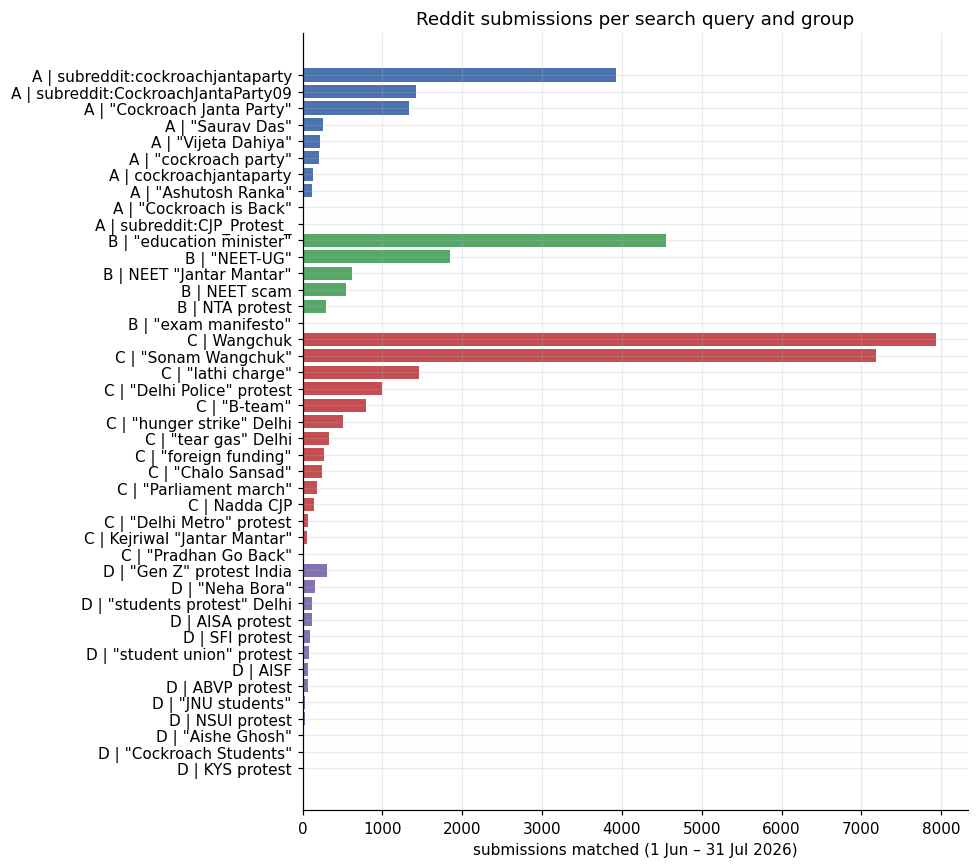

,group,query,matched,new
38,A,subreddit:cockroachjantaparty,3925,3386
39,A,subreddit:CockroachJantaParty09,1421,1089
0,A,"""Cockroach Janta Party""",1333,1333
3,A,"""Saurav Das""",262,141
5,A,"""Vijeta Dahiya""",213,160
1,A,"""cockroach party""",212,193
2,A,cockroachjantaparty,130,107
4,A,"""Ashutosh Ranka""",124,43
6,A,"""Cockroach is Back""",7,4
40,A,subreddit:CJP_Protest_,0,0


In [6]:
# Which queries found what (submissions per query, with the share that is new to that query)
per_q = pd.DataFrame([{'group': k.split('|')[0], 'query': k.split('|', 1)[1], **v} for k, v in state.get('queries_done', {}).items()])
if len(per_q):
    per_q = per_q.sort_values(['group', 'matched'], ascending=[True, False]).drop(columns=['ts'])
    save_table(per_q, '01_reddit_submissions_per_query')
    fig, ax = plt.subplots(figsize=(9, 8))
    y = per_q['group'] + ' | ' + per_q['query']
    ax.barh(y, per_q['matched'], color=[PALETTE[g] for g in per_q['group']])
    ax.invert_yaxis(); ax.set_xlabel('submissions matched (1 Jun – 31 Jul 2026)'); ax.set_title('Reddit submissions per search query and group')
    savefig('01_reddit_submissions_per_query'); plt.show()
per_q

figure saved: outputs/figures/01_reddit_daily_submissions.png


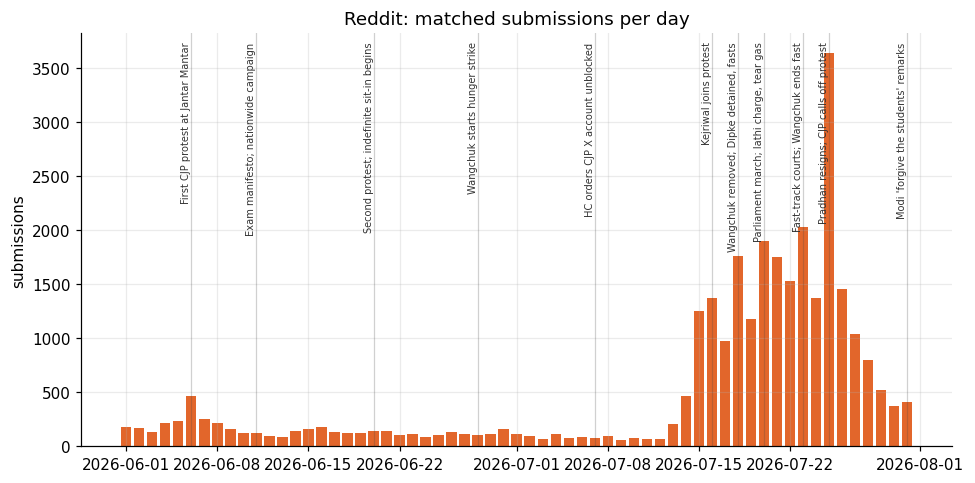

table saved: outputs/tables/01_reddit_top_subreddits.csv  (2936 rows)


,submissions,comments
subreddit,,
cockroachjantaparty,4021,10739
CockroachJantaParty09,1437,1383
india,1127,15248
TeenIndia,1022,12497
delhi,987,17203
TwentiesIndia,785,16171
IndianFocus,748,14057
JEENEETards,607,6347
IndianTeenagers,595,7942


In [7]:
# Daily volume of matched Reddit submissions and the subreddits where the discussion happened
if subs:
    sd = pd.DataFrame({'ts': pd.to_datetime([d['created_utc'] for d in subs], unit='s'), 'subreddit': [d.get('subreddit', '') for d in subs],
                       'num_comments': [d.get('num_comments') or 0 for d in subs]})
    daily = sd.set_index('ts').resample('D').size()
    fig, ax = plt.subplots()
    ax.bar(daily.index, daily.values, color=PALETTE['reddit'], width=0.8)
    ax.set_title('Reddit: matched submissions per day'); ax.set_ylabel('submissions')
    annotate_events(ax); savefig('01_reddit_daily_submissions'); plt.show()
    top_subs = sd.groupby('subreddit').agg(submissions=('ts', 'size'), comments=('num_comments', 'sum')).sort_values('submissions', ascending=False)
    save_table(top_subs.reset_index(), '01_reddit_top_subreddits')
    display(top_subs.head(25))

**What this shows:** the Reddit discussion is spread over general Indian subreddits (r/india, r/unitedstatesofindia, r/delhi, r/IndiaSpeaks …) and three CJP-specific subreddits; the daily curve follows the same protest events as X (6 June, 20 June, 18–25 July).

## 3. Ethics and limits
Only public posts were collected; no private data, no login-protected content. Reddit archives may miss posts removed quickly by moderators, and X capture depends on what the search interface returned while scrolling, so both samples are partial. Author handles are kept because they are needed for the network, but the report discusses results at community level.